# Which genes switch on when a mouse makes milk?

The **mammary gland** changes enormously during pregnancy and when the mother feeds her young (**lactation**). It is built from two kinds of cells:

* **luminal cells** line the inside of the milk ducts and, during lactation, **produce the milk**,
* **basal cells** sit around them and **squeeze** the milk out, like a muscle.

Researchers (Fu et al. 2015) took both cell types from mice in three states: **virgin** (never pregnant), **pregnant** and **lactating**, with two mice per combination. They sequenced the RNA of these **12 samples**.

### Our research question

> Which genes do the **luminal cells** switch on (or off) when they go from **pregnancy** to **making milk**? Can we explain what milk is made of from these genes?

### The plan

```mermaid
flowchart LR
    A[1 Look at<br>the data] --> B[2 Define<br>groups] --> C[3 Prepare:<br>filter, normalise] --> D[4 Design and<br>contrasts] --> E[5 Test<br>with limma] --> F[6 Interpret]
```

Run the cells one after the other, from the top, with **Shift + Enter**.

In [1]:
setLanguage("en")   # language of the messages and plots below

Language: English



## 1 Look at the data

`loadDataset` loads the data. It contains three tables: `samples` (what each sample is), `counts` (the reads) and `genes` (gene names). Let's look at the samples first.

In [2]:
data <- loadDataset("milk")
data$samples

Loaded data set 'milk': 27179 genes, 12 samples.



,sample,celltype,state
,<chr>,<fct>,<fct>
MCL1-DG,MCL1-DG,basal,virgin
MCL1-DH,MCL1-DH,basal,virgin
MCL1-DI,MCL1-DI,basal,pregnant
MCL1-DJ,MCL1-DJ,basal,pregnant
MCL1-DK,MCL1-DK,basal,lactating
MCL1-DL,MCL1-DL,basal,lactating
MCL1-LA,MCL1-LA,luminal,virgin
MCL1-LB,MCL1-LB,luminal,virgin
MCL1-LC,MCL1-LC,luminal,pregnant


Each sample has a name (`MCL1-DG` …), a cell type (`celltype`) and a state (`state`). The names in the table are in English, so `lactating` means "säugend" and `pregnant` "trächtig".

Now the counts. `head()` shows only the first 6 rows; the full table is much longer.

In [3]:
head(data$counts)

,MCL1-DG,MCL1-DH,MCL1-DI,MCL1-DJ,MCL1-DK,MCL1-DL,MCL1-LA,MCL1-LB,MCL1-LC,MCL1-LD,MCL1-LE,MCL1-LF
497097,438,300,65,237,354,287,0,0,0,0,0,0
100503874,1,0,1,1,0,4,0,0,0,0,0,0
100038431,0,0,0,0,0,0,0,0,0,0,0,0
19888,1,1,0,0,0,0,10,3,10,2,0,0
20671,106,182,82,105,43,82,16,25,18,8,3,10
27395,309,234,337,300,290,270,560,464,489,328,307,342


Each **row** is a gene (the numbers on the left are gene IDs from the NCBI database), each **column** a sample, and each number says how many reads of that gene were found in that sample. The `genes` table translates the IDs into gene names:

In [4]:
head(data$genes)

,gene_id,symbol,description
,<int>,<chr>,<chr>
497097,497097,Xkr4,X-linked Kx blood group related 4
100503874,100503874,Gm19938,"predicted gene, 19938"
100038431,100038431,Gm10568,predicted gene 10568
19888,19888,Rp1,retinitis pigmentosa 1 (human)
20671,20671,Sox17,SRY (sex determining region Y)-box 17
27395,27395,Mrpl15,mitochondrial ribosomal protein L15


**Exercise:** How many genes and how many samples are in the count table? `dim()` gives the size of a table: first the number of rows, then of columns.

In [5]:
dim(data$counts)

[1] 27179    12

✅ **Answer:** **27,179 genes** (rows) and **12 samples** (columns): 2 cell types × 3 states × 2 mice.

For the analysis, we put the three tables into one container, a `DGEList` from the package **edgeR**. It also adds up the reads of each sample: the **library size**.

In [6]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dge$samples

,group,lib.size,norm.factors,sample,celltype,state
,<fct>,<dbl>,<dbl>,<chr>,<fct>,<fct>
MCL1-DG,1,23227641,1,MCL1-DG,basal,virgin
MCL1-DH,1,21777891,1,MCL1-DH,basal,virgin
MCL1-DI,1,24100765,1,MCL1-DI,basal,pregnant
MCL1-DJ,1,22665371,1,MCL1-DJ,basal,pregnant
MCL1-DK,1,21529331,1,MCL1-DK,basal,lactating
MCL1-DL,1,20015386,1,MCL1-DL,basal,lactating
MCL1-LA,1,20392113,1,MCL1-LA,luminal,virgin
MCL1-LB,1,21708152,1,MCL1-LB,luminal,virgin
MCL1-LC,1,22241607,1,MCL1-LC,luminal,pregnant


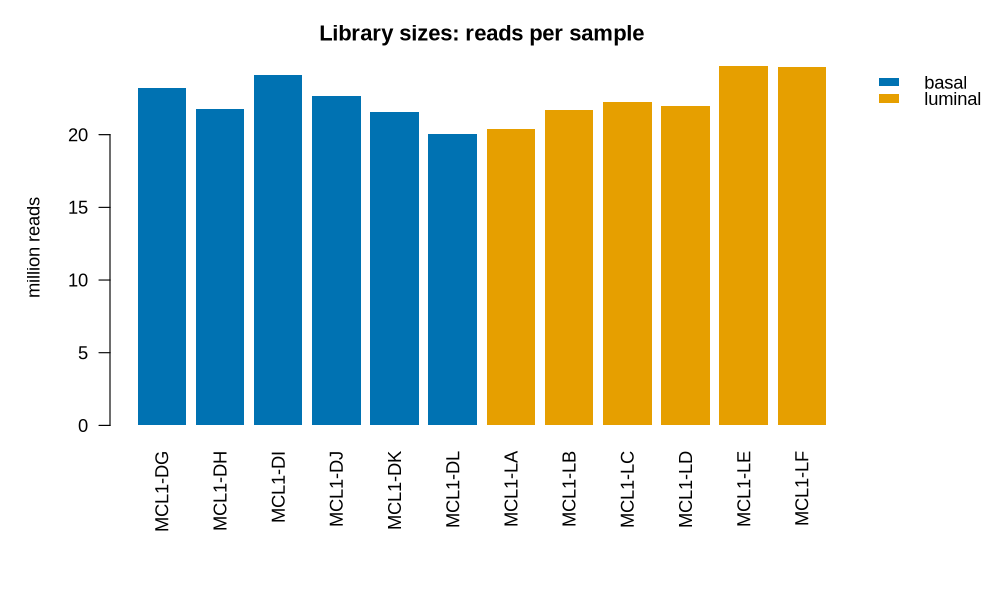

In [7]:
plotLibrarySizes(dge, colour_by = "celltype")

**Question:** Do all samples have the same number of reads? Why would it be wrong to compare the raw counts of a gene between two samples?

✅ **Answer:** No: between about **20 and 25 million** reads. A sample with 25 million reads has about 25 % more reads for *every* gene than one with 20 million, even if the cells are identical. So we must compare **proportions** (reads per million), not raw counts.

**Exercise:** Many genes are not used at all in these cells. How many genes have **0 reads in all 12 samples**? `rowSums()` adds up each row, and `sum(... == x)` counts how often something equals `x`.

In [8]:
sum(rowSums(dge$counts) == 0)

[1] 5787

✅ **Answer:** **5,787 genes** have no read at all. Mammary gland cells simply don't use them (for example genes only used in the brain or liver).

## 2 Define the groups

To compare, limma has to know which samples belong together. Each combination of cell type and state is one **group**, for example `luminal_lactating`. We glue the two columns together with `paste` and store the result in the `group` column.

In [9]:
group <- paste(dge$samples$celltype, dge$samples$state, sep = "_")
dge$samples$group <- factor(group, levels = unique(group))
table(dge$samples$group)


     basal_virgin    basal_pregnant   basal_lactating    luminal_virgin  luminal_pregnant luminal_lactating 
                2                 2                 2                 2                 2                 2 

**Question:** How many samples does each group have? Why do researchers use several mice per group (**replicates**) instead of one?

✅ **Answer:** **6 groups with 2 samples each.** With only one mouse per group we couldn't tell whether a difference comes from the condition or just from the fact that every mouse is a bit different. Replicates show how large this natural variation is; limma compares each difference with it.

Let's look at a single gene. **Csn2** is the gene for **β-casein**, the main protein in milk. `plotGene` shows its expression in every sample as **log2 counts per million**: going up by 1 means twice as much. Where do you expect it to be high?

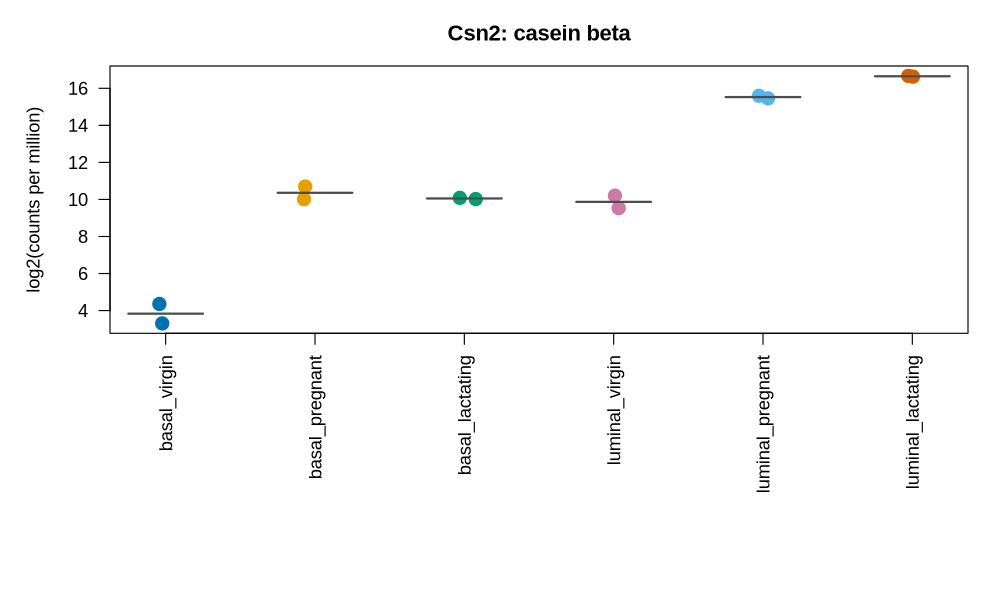

In [10]:
plotGene(dge, "Csn2", group_by = "group")

**Exercise:** Use your biology to check that the samples are labelled correctly. **Krt5** (keratin 5) is a typical protein of basal cells, **Krt8** (keratin 8) of luminal cells. Plot one of them.

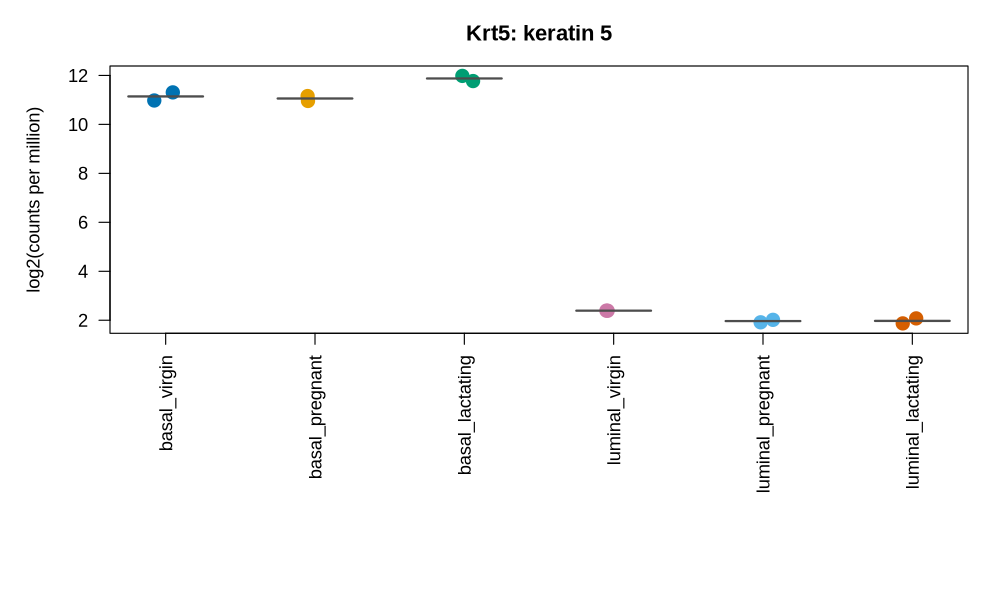

In [11]:
plotGene(dge, "Krt5", group_by = "group")

✅ **Answer:** Csn2 is low in virgin mice, much higher in pregnancy and highest in **lactating luminal cells** (about 2¹³ ≈ 8,000 times more than in basal cells of virgin mice!). Krt5 is high in all **basal** samples and low in luminal ones (Krt8 the other way round). So the labels make sense.

## 3 Prepare the data

### Filtering

Genes with only a handful of reads can't be tested reliably: 0 vs. 2 reads could easily be chance. `filterByExpr` keeps only genes with enough reads in at least as many samples as the smallest group has (here 2). `TRUE` means keep.

In [12]:
keep <- filterByExpr(dge)
table(keep)

keep
FALSE  TRUE 
11210 15969 

In [13]:
dge <- dge[keep, , keep.lib.sizes = FALSE]
dim(dge)

[1] 15969    12

### Normalisation

Now let's look at the distribution of **all** genes in each sample. Each box shows the middle half of the genes; the line in the box is the median. If the samples are comparable, the boxes should be at about the same height.

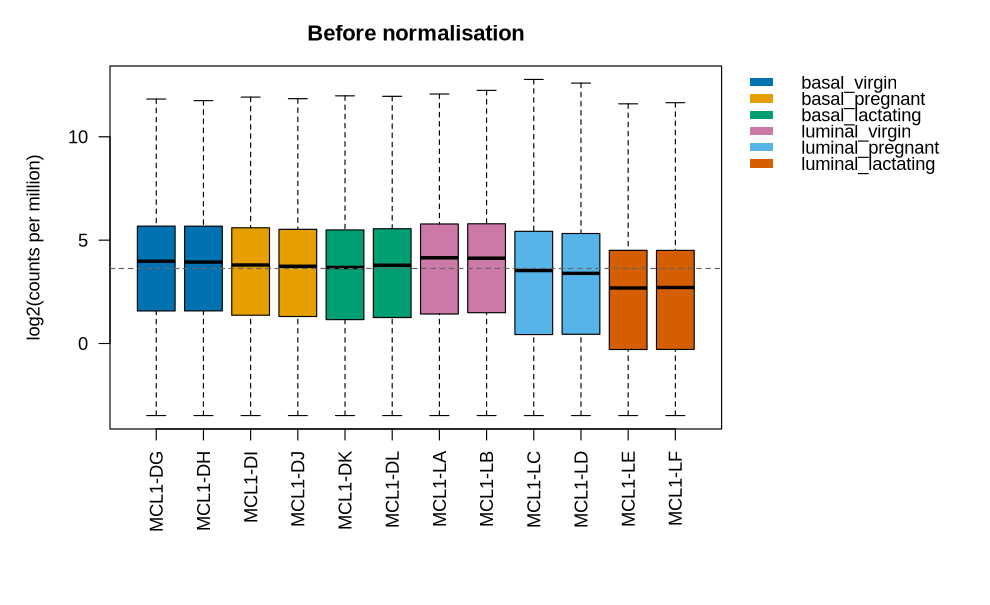

In [14]:
plotDistributions(dge, colour_by = "group", title = "Before normalisation")

Look at the two lactating luminal samples (`MCL1-LE`, `MCL1-LF`): their boxes are **lower**. Are all their genes really less active? No! These cells spend a huge part of their RNA on a few milk genes. Calculate the share of reads for Csn2 alone (gene ID 12991) in sample `MCL1-LE`:

In [15]:
data$counts["12991", "MCL1-LE"] / sum(data$counts[, "MCL1-LE"])   # share of all reads

[1] 0.1041865

About **10 %** of all reads come from this one gene. Then fewer reads are left for all the other genes, and they *look* lower. The **TMM normalisation** in `normLibSizes` corrects this: it calculates a correction factor for each sample (`norm.factors`) from the many genes that don't change.

In [16]:
dge <- normLibSizes(dge)
dge$samples[, c("group", "lib.size", "norm.factors")]

,group,lib.size,norm.factors
,<fct>,<dbl>,<dbl>
MCL1-DG,basal_virgin,23219195,1.2384285
MCL1-DH,basal_virgin,21769326,1.2137919
MCL1-DI,basal_pregnant,24092719,1.1248001
MCL1-DJ,basal_pregnant,22657703,1.0711828
MCL1-DK,basal_lactating,21522881,1.0362789
MCL1-DL,basal_lactating,20009184,1.0869418
MCL1-LA,luminal_virgin,20385437,1.3681957
MCL1-LB,luminal_virgin,21699830,1.3649435
MCL1-LC,luminal_pregnant,22236469,1.0039770


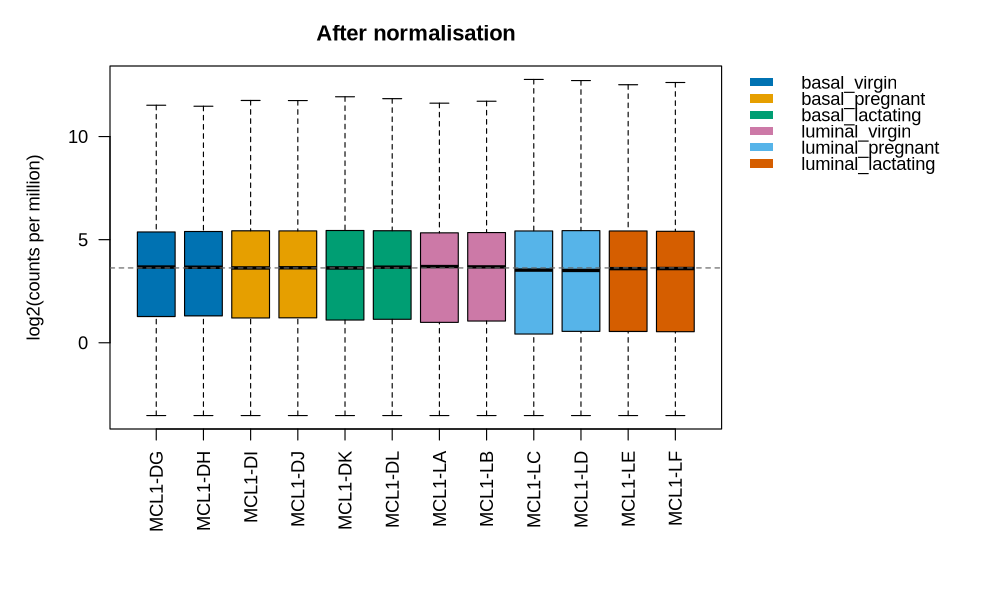

In [17]:
plotDistributions(dge, colour_by = "group", title = "After normalisation")

**Question:** How many genes are left after filtering? Which samples get the smallest correction factor, and what changed in the box plot?

✅ **Answer:** **15,969 genes** of 27,179 remain. The lactating luminal samples LE and LF get the smallest factor (about **0.53**): their library size is effectively halved, to make up for the reads used by the milk genes. After normalisation, all boxes are at about the same height.

### The sample map (MDS)

Before testing single genes, let's see how similar the samples are **overall**. An **MDS plot** puts each sample on a map: samples whose ~16,000 genes are expressed similarly lie close together. **Distance 1** (left–right) is the direction in which the samples differ most; the percentage says how much of all differences it shows.

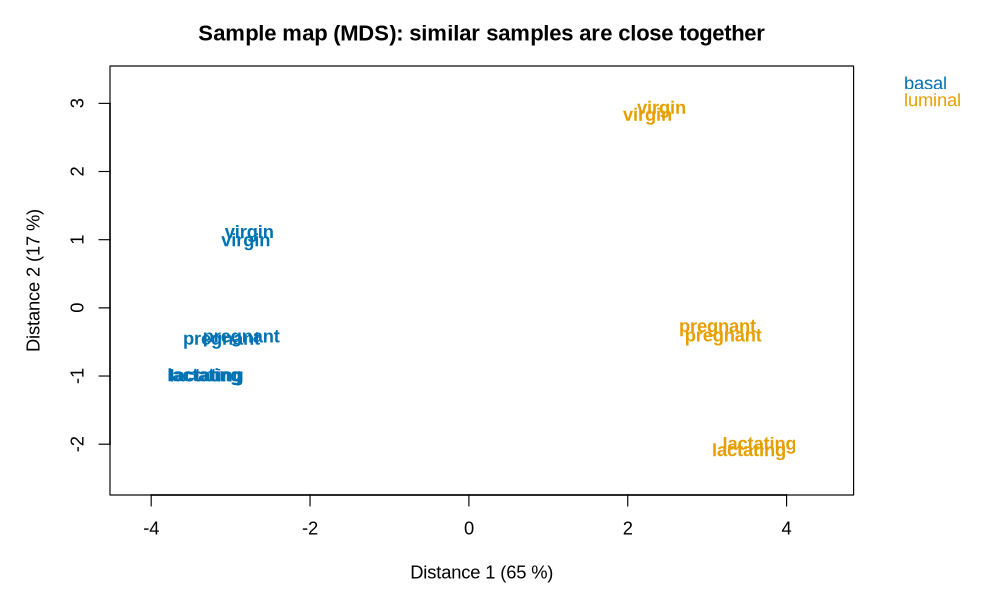

In [18]:
plotSamples(dge, colour_by = "celltype", label_by = "state")

**Exercise:** Now colour the samples by state and label them by cell type.

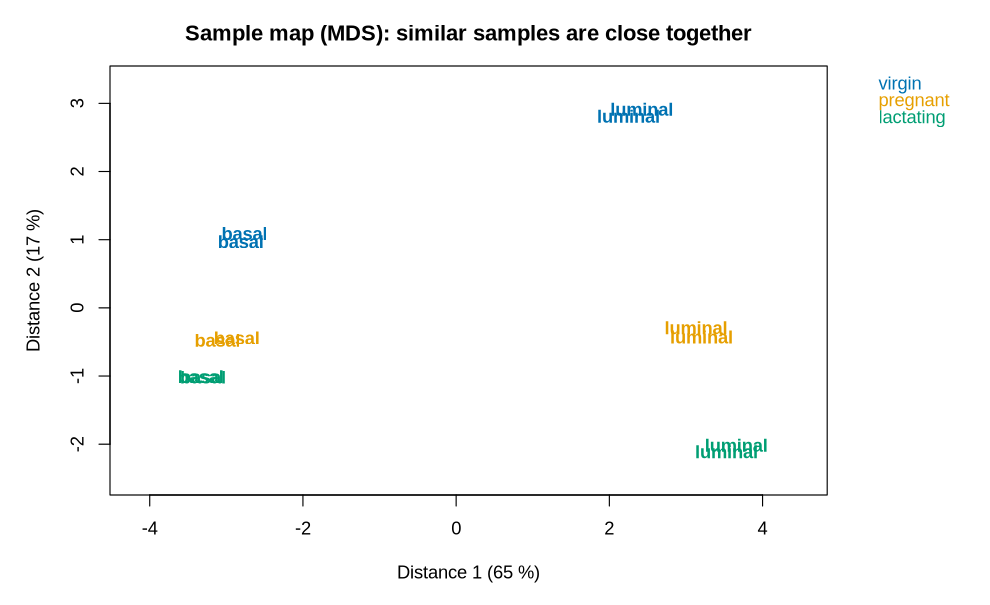

In [19]:
plotSamples(dge, colour_by = "state", label_by = "celltype")

**Question:** What separates the samples along distance 1, and what along distance 2? Do the two replicates of each group lie close together? Why is that good news?

✅ **Answer:** Distance 1 (**65 %**) separates **basal from luminal** cells: the cell type is by far the biggest difference. Distance 2 (**17 %**) sorts the samples by state: virgin → pregnant → lactating, and the change is larger in luminal cells. The replicates lie close together, so the experiment worked well and no samples were mixed up.

## 4 Design and contrasts

### The design matrix

The **design matrix** tells limma which group each sample belongs to: one column per group, with a 1 if the sample belongs to it.

In [20]:
design <- model.matrix(~0 + group, data = dge$samples)
colnames(design) <- levels(dge$samples$group)
design

,basal_virgin,basal_pregnant,basal_lactating,luminal_virgin,luminal_pregnant,luminal_lactating
MCL1-DG,1,0,0,0,0,0
MCL1-DH,1,0,0,0,0,0
MCL1-DI,0,1,0,0,0,0
MCL1-DJ,0,1,0,0,0,0
MCL1-DK,0,0,1,0,0,0
MCL1-DL,0,0,1,0,0,0
MCL1-LA,0,0,0,1,0,0
MCL1-LB,0,0,0,1,0,0
MCL1-LC,0,0,0,0,1,0
MCL1-LD,0,0,0,0,1,0


### Contrasts: which groups do we compare?

A **contrast** is the comparison you are interested in, written as a subtraction: `A - B` asks "how is A different from B?". A **positive** log fold change then means **higher in A**.

Our question compares **lactating** with **pregnant** luminal cells. Why not simply all lactating with all pregnant samples? Because basal cells don't make milk, and mixing them in would blur the result: the MDS plot showed that the cell type is the biggest difference of all.

**Exercise:** Fill in the two contrasts:
1. `lactating_vs_pregnant`: luminal cells, lactating compared with pregnant,
2. `luminal_vs_basal`: in virgin mice, luminal compared with basal cells.

Use the group names exactly as in the design matrix.

In [21]:
contrasts <- makeContrasts(
    lactating_vs_pregnant = luminal_lactating - luminal_pregnant,
    luminal_vs_basal      = luminal_virgin - basal_virgin,
    levels = design)
contrasts

,lactating_vs_pregnant,luminal_vs_basal
basal_virgin,0,-1
basal_pregnant,0,0
basal_lactating,0,0
luminal_virgin,0,1
luminal_pregnant,-1,0
luminal_lactating,1,0


**Question:** In `lactating_vs_pregnant`, what does a log fold change of **+3** mean for a gene? And **−1**? Which contrast would you write to find the genes that change in **basal** cells during pregnancy?

✅ **Answer:** **+3**: the gene is 2³ = **8 times higher** in lactating than in pregnant luminal cells. **−1**: it is **half** as high. For basal cells in pregnancy: `basal_pregnant - basal_virgin`.

## 5 Test every gene with limma

Three steps:

1. **`voom`** turns the counts into log2 counts per million and works out how reliable each value is: genes with few reads are noisier, so they get less weight. The plot shows this: the fewer reads (left), the larger the variation (up).
2. **`lmFit`** calculates the average of every gene in every group, and **`contrasts.fit`** the differences we asked for in the contrasts.
3. **`eBayes`** tests whether each difference is larger than the natural variation between the replicates. With only 2 replicates that variation is hard to estimate for a single gene, so limma "borrows" information from all the other genes. That's what makes limma work with small experiments.

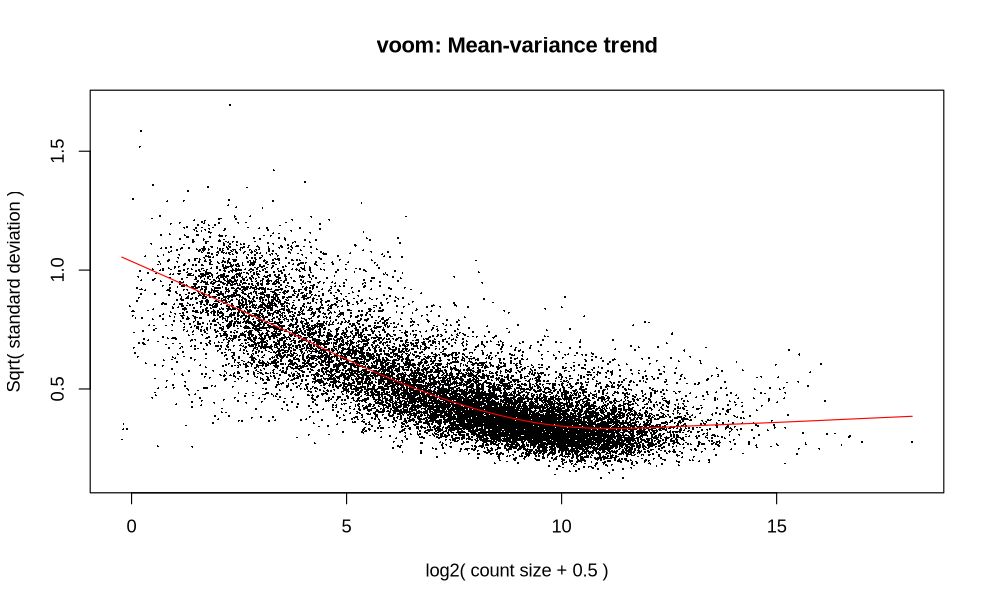

In [22]:
v <- voom(dge, design, plot = TRUE)

In [23]:
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)

### How many genes changed?

For each gene, limma calculates a **p-value**: how likely is a difference this large if the gene didn't really change? Small = convincing.

But careful: we test about 16,000 genes. With the usual limit p < 0.05, about 5 % of the genes that **don't** change would still look significant by chance: that's 800 false hits! That's why limma also gives an **adjusted p-value** (`adj.P.Val`). If we take all genes with adjusted p < 0.05, only about 5 % of **this list** are false hits.

`decideTests` counts the genes with adjusted p < 0.05: up, down or not significant (`NotSig`).

In [24]:
summary(decideTests(fit))

       lactating_vs_pregnant luminal_vs_basal
Down                    3679             5121
NotSig                  8604             5746
Up                      3686             5102

**Question:** How many genes go up and down from pregnancy to lactation? Which of the two contrasts has more changed genes, and does that fit the MDS plot?

✅ **Answer:** Lactating vs pregnant: about **3,700 up** and **3,700 down**. Luminal vs basal: about **5,100 up** and **5,100 down**, even more. That fits the MDS plot, where the cell type (distance 1) was the biggest difference. Thousands of significant genes are normal in such a big biological change; that's why the next step is to look at the **strongest** ones.

## 6 Interpret the results

### The volcano plot

In a **volcano plot** every gene is a dot. Left–right is the log fold change (left: lower when lactating, right: higher), and up is how certain the result is. The most interesting genes are at the top left and top right: a big change **and** convincing. Coloured dots are significant and change at least 2-fold (dashed lines).

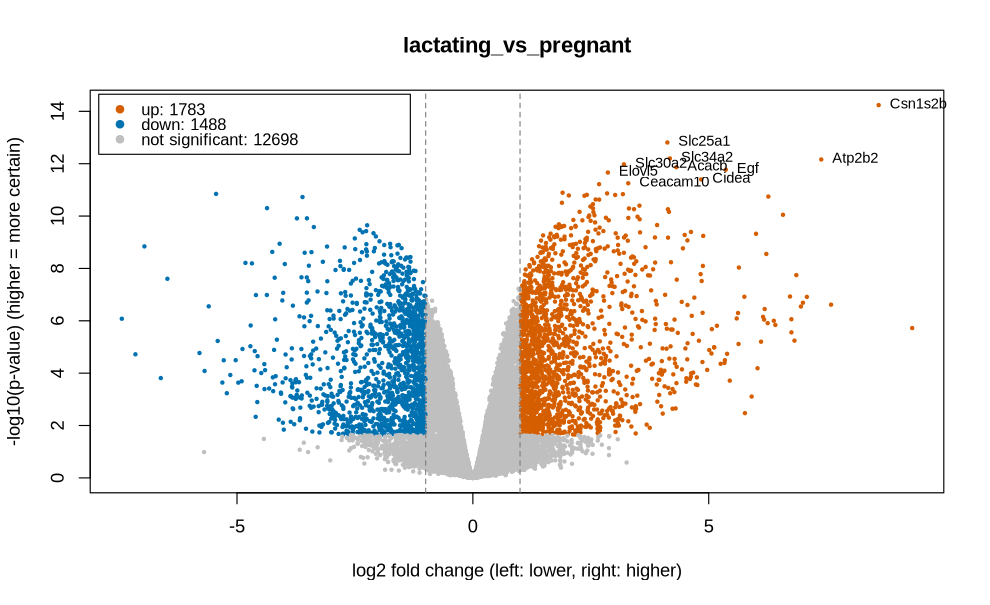

In [25]:
plotVolcano(fit, "lactating_vs_pregnant")

### The top genes

`showTop` lists the most convincing genes with their name and description. `change` translates the log fold change back into "times higher/lower".

In [26]:
showTop(fit, "lactating_vs_pregnant", n = 15, direction = "up")

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Csn1s2b,casein alpha s2-like B,8.60,388.7× higher,3.6,9.2e-11
Slc25a1,solute carrier family 25 (mitochondrial car…,4.12,17.4× higher,5.8,1.2e-09
Slc34a2,solute carrier family 34 (sodium phosphate)…,4.18,18.1× higher,4.3,2.8e-09
Atp2b2,"ATPase, Ca++ transporting, plasma membrane 2",7.39,167.2× higher,1.3,2.8e-09
Slc30a2,solute carrier family 30 (zinc transporter)…,3.20,9.2× higher,2.7,3.4e-09
Acacb,acetyl-Coenzyme A carboxylase beta,4.31,19.9× higher,4.4,3.6e-09
Egf,epidermal growth factor,5.36,41.1× higher,0.7,3.9e-09
Elovl5,ELOVL fatty acid elongase 5,2.86,7.3× higher,6.5,4.3e-09
Cidea,cell death-inducing DNA fragmentation facto…,4.84,28.6× higher,3.4,7.1e-09


**Exercise:** Choose a gene from the list that interests you and look at it in all groups.

Find out what it does: search for its name on [GeneCards](https://www.genecards.org) (for human genes; the mouse gene usually does the same), [NCBI Gene](https://www.ncbi.nlm.nih.gov/gene) or [UniProt](https://www.uniprot.org), or think about the description. *Tip: milk contains protein (caseins), fat, milk sugar (lactose), calcium, zinc and phosphate.*

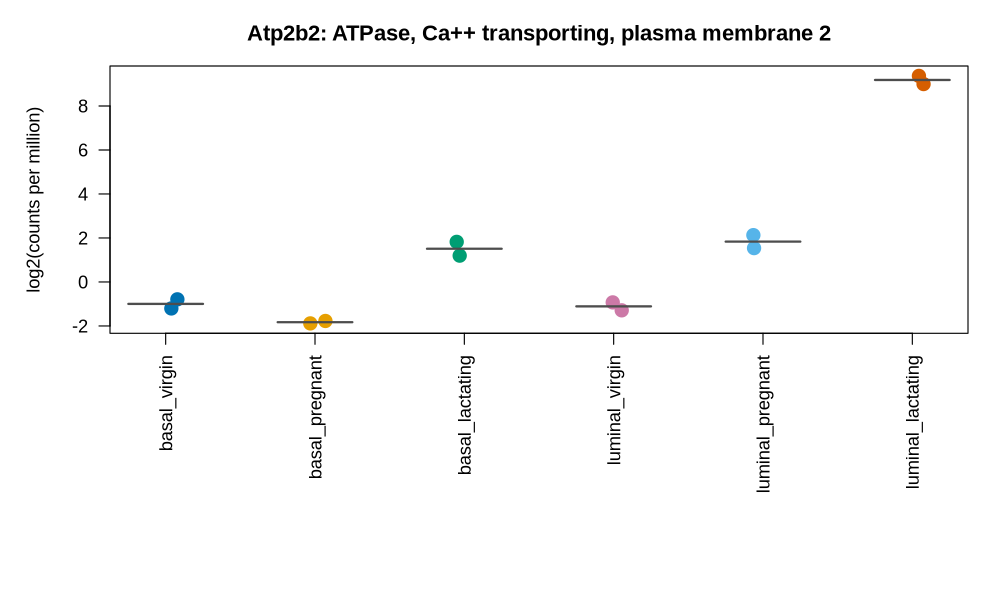

In [27]:
plotGene(dge, "Atp2b2", group_by = "group")

**Question:** Can you connect the top genes to what milk is made of? Find at least three examples.

✅ **Answer:** * **Protein:** *Csn1s2b* is a **casein**, a milk protein (≈ 390 times higher).
* **Calcium:** *Atp2b2* is a calcium pump that moves calcium **into the milk** (≈ 170 times higher).
* **Zinc and phosphate:** *Slc30a2* transports zinc, *Slc34a2* phosphate into the milk.
* **Fat:** *Acacb*, *Elovl5* and *Pmvk* make fatty acids and other fats; *Cidea* helps package fat into the droplets that make up milk fat; *Slc25a1* supplies the building material for fatty acids.

So the luminal cells switch on a whole **milk factory**: genes for every component of milk.

Where are the famous milk genes like **Wap** (whey acidic protein) and **Lalba** (α-lactalbumin, needed to make lactose)? Look at one of them:

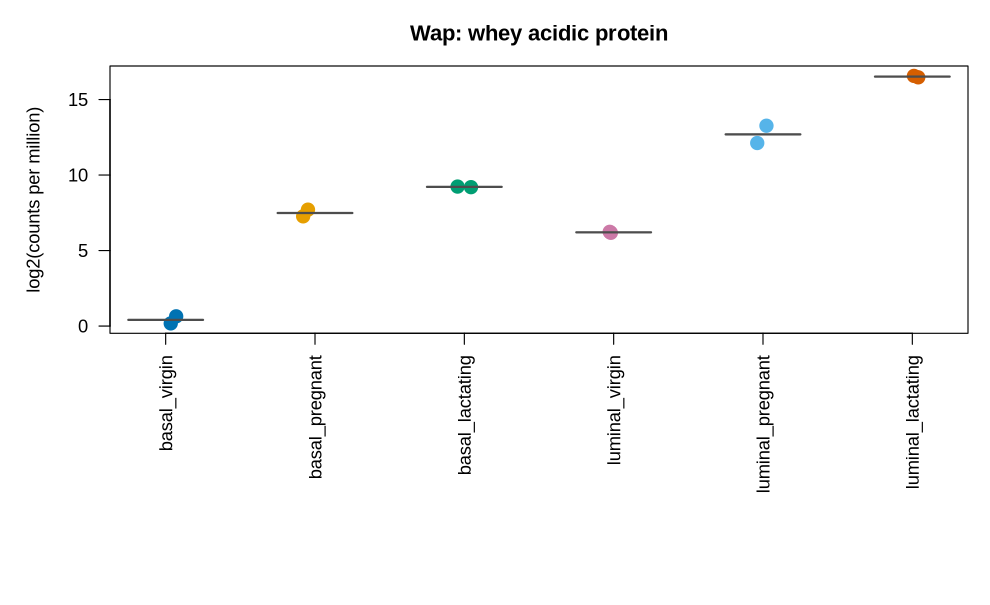

In [28]:
plotGene(dge, "Wap", group_by = "group")

**Question:** Wap is significantly higher in lactating cells, but it is not at the top of the list. Why not?

✅ **Answer:** Wap is already **very high in pregnancy**: the gland prepares for milk production before birth. From pregnancy to lactation it only rises about 14-fold (logFC ≈ 3.8), less than the top genes. The list is sorted by how convincing the change is, not by how highly a gene is expressed.

Now the genes that go **down**:

In [29]:
showTop(fit, "lactating_vs_pregnant", n = 10, direction = "down")

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Rbp1,"retinol binding protein 1, cellular",-5.44,43.5× lower,6.1,1.4e-08
Ppl,periplakin,-3.61,12.2× lower,6.4,1.4e-08
Slc39a4,solute carrier family 39 (zinc transporter)…,-4.36,20.6× lower,2.7,2.7e-08
Acot1,acyl-CoA thioesterase 1,-3.52,11.5× lower,5.7,4.4e-08
BC006965,cDNA sequence BC006965,-3.73,13.3× lower,4.2,4.4e-08
Tbc1d9,"TBC1 domain family, member 9",-2.24,4.7× lower,6.3,6.8e-08
Anpep,"alanyl aminopeptidase, membrane",-3.37,10.3× lower,6.5,7.0e-08
Sox4,SRY (sex determining region Y)-box 4,-2.40,5.3× lower,7.5,8.1e-08
Cldn3,claudin 3,-2.26,4.8× lower,5.2,8.8e-08


### Your conclusion

**Exercise:** Answer the research question in two or three sentences, as you would in a lab report: what did you compare, what did you find, and what does it mean?

✅ **Answer:** We compared luminal cells of lactating and pregnant mice (2 mice each) with limma. About 3,700 genes went up and 3,700 down significantly. The strongest increases were in genes for every component of milk: caseins (protein), fat production and fat droplets, and transporters for calcium, zinc and phosphate. So at the start of lactation the luminal cells switch on a complete milk production programme. Genes going down include some for growth and development (e.g. *Sox4*): the gland has finished growing and now concentrates on making milk.

### Bonus: luminal vs basal cells

Look at the second contrast. Which genes make a basal cell a basal cell?

In [30]:
showTop(fit, "luminal_vs_basal", n = 15)

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Dll1,delta like canonical Notch ligand 1,-6.42,85.8× lower,5.9,2.3e-11
Postn,"periostin, osteoblast specific factor",-7.58,191.2× lower,7.9,2.3e-11
Col4a2,"collagen, type IV, alpha 2",-5.54,46.5× lower,7.6,2.3e-11
Krt5,keratin 5,-8.93,486.1× lower,6.7,2.3e-11
Stc2,stanniocalcin 2,5.67,51.0× higher,4.0,5.7e-11
Antxr1,anthrax toxin receptor 1,-7.35,162.9× lower,5.7,5.7e-11
Prlr,prolactin receptor,6.62,98.5× higher,5.0,5.9e-11
Aebp1,AE binding protein 1,-5.80,55.7× lower,4.8,6.2e-11
Acta2,"actin alpha 2, smooth muscle, aorta",-8.58,383.2× lower,8.9,6.2e-11


✅ **Answer:** Negative logFC = higher in **basal** cells: *Krt5* (keratin 5, almost 500 times higher), collagen *Col4a2* and *Postn* (the connective tissue around the ducts), *Dll1* (Notch signalling). Positive = higher in **luminal** cells: *Prlr*, the receptor for the hormone **prolactin**, which tells the luminal cells to make milk, and *Stc2*.

**Well done!** 🎉 You've done a complete differential expression analysis, the same way researchers do it. Now it's your turn: choose one of the notebooks `02_diy_…`, `03_diy_…` or `04_diy_…` and answer a new research question on your own.

## Sources

**Data**
* **Milk (tutorial):** Fu NY, Rios AC, Pal B, et al. (2015). EGF-mediated induction of Mcl-1 at the switch to lactation is essential for alveolar cell survival. *Nature Cell Biology* 17:365–375. [doi:10.1038/ncb3117](https://doi.org/10.1038/ncb3117). Counts from GEO [GSE60450](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE60450).
* **Dexamethasone (airway):** Himes BE, Jiang X, Wagner P, et al. (2014). RNA-Seq transcriptome profiling identifies CRISPLD2 as a glucocorticoid responsive gene that modulates cytokine function in airway smooth muscle cells. *PLoS ONE* 9(6):e99625. [doi:10.1371/journal.pone.0099625](https://doi.org/10.1371/journal.pone.0099625). Counts from the Bioconductor package [airway](https://bioconductor.org/packages/airway) (Love M).
* **Pasilla:** Brooks AN, Yang L, Duff MO, et al. (2011). Conservation of an RNA regulatory map between *Drosophila* and mammals. *Genome Research* 21:193–202. [doi:10.1101/gr.108662.110](https://doi.org/10.1101/gr.108662.110). Counts from the Bioconductor package [pasilla](https://bioconductor.org/packages/pasilla).
* **Breast cancer:** The Cancer Genome Atlas Network (2012). Comprehensive molecular portraits of human breast tumours. *Nature* 490:61–70. [doi:10.1038/nature11412](https://doi.org/10.1038/nature11412). Counts (STAR – Counts) of 10 TCGA-BRCA patients from the [NCI Genomic Data Commons](https://portal.gdc.cancer.gov).
* **Gene names:** Bioconductor annotation packages org.Mm.eg.db, org.Hs.eg.db, org.Dm.eg.db (Carlson M).

**Software and method**
* **limma:** Ritchie ME, Phipson B, Wu D, et al. (2015). limma powers differential expression analyses for RNA-sequencing and microarray studies. *Nucleic Acids Research* 43(7):e47. [doi:10.1093/nar/gkv007](https://doi.org/10.1093/nar/gkv007)
* **voom:** Law CW, Chen Y, Shi W, Smyth GK (2014). voom: precision weights unlock linear model analysis tools for RNA-seq read counts. *Genome Biology* 15:R29. [doi:10.1186/gb-2014-15-2-r29](https://doi.org/10.1186/gb-2014-15-2-r29)
* **edgeR:** Chen Y, Chen L, Lun ATL, Baldoni PL, Smyth GK (2025). edgeR v4: powerful differential analysis of sequencing data with expanded functionality and improved support for small counts and larger datasets. *Nucleic Acids Research* 53(2):gkaf018. [doi:10.1093/nar/gkaf018](https://doi.org/10.1093/nar/gkaf018)
* **Workflow this practical follows:** Law CW, Alhamdoosh M, Su S, et al. (2016). RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR. *F1000Research* 5:1408. [doi:10.12688/f1000research.9005.3](https://doi.org/10.12688/f1000research.9005.3)